## Benchmark de Nelder-Mead sur les 3 fonctions de test

Pour chaque fonction, on lance Nelder-Mead jusqu'à ce que f < SEUIL (ou jusqu'au nombre maximum d'itérations), et on mesure :
- le nombre d'**évaluations de f** (le vrai coût de la méthode) ;
- la **précision** : f final et distance au vrai minimum ;
- le **temps**.

Les paramètres sont regroupés dans la cellule suivante : il suffit de les modifier et de relancer le notebook pour tester d'autres réglages.

In [1]:
%matplotlib widget
import time
import numpy as np
import matplotlib.pyplot as plt

from algo.neldermead import NelderMead
from utils.point import Point

# ---------- Paramètres modifiables ----------
ALPHA, GAMMA, RHO, SIGMA = 1, 2, 0.5, 0.5   # coefficients de Nelder-Mead
H = 0.5                                     # taille du simplexe initial
SEUIL = 1e-8                                # arrêt quand f < SEUIL
ITER_MAX = 3000                             # sécurité si le seuil n'est jamais atteint

In [2]:
def rosenbrock(p):
    return (1 - p[0])**2 + 100*(p[1] - p[0]**2)**2

def powell(p):
    return (p[0] + 10*p[1])**2 + 5*(p[2] - p[3])**2 + (p[1] - 2*p[2])**4 + 10*(p[0] - p[3])**4

def quartique(p):
    return sum(p[i]**4 for i in range(p.dimension))

# nom : (fonction, point de départ, minimum connu)
FONCTIONS = {
    "Rosenbrock (2D)": (rosenbrock, [-1.2, 1], [1, 1]),
    "Powell (4D)":     (powell, [3, -1, 0, 1], [0]*4),
    "Quartique (10D)": (quartique, [1]*10, [0]*10),
}

In [3]:
def simplexe_initial(x, h):
    """Le point x, puis x décalé de h sur une seule coordonnée pour chaque autre sommet"""
    points = [Point(list(x))]
    for i in range(len(x)):
        y = list(x)
        y[i] += h
        points.append(Point(y))
    return points

def benchmark(f, x0, x_min):
    """Lance Nelder-Mead et renvoie les mesures + l'historique de f"""
    deja_calcules = {}               # on ne compte qu'une fois chaque point évalué

    def f_comptee(p):
        cle = tuple(p.values)
        if cle not in deja_calcules:
            deja_calcules[cle] = f(p)
        return deja_calcules[cle]

    algo = NelderMead(simplexe_initial(x0, H), f_comptee, ALPHA, GAMMA, RHO, SIGMA)
    historique = []                  # (nb d'évaluations, meilleure valeur de f)

    debut = time.perf_counter()
    for k in range(ITER_MAX):
        algo.compute(1)
        meilleur = min(algo.points, key=f_comptee)
        historique.append((len(deja_calcules), f_comptee(meilleur)))
        if f_comptee(meilleur) < SEUIL:
            break
    duree = time.perf_counter() - debut

    distance = np.linalg.norm(np.array(meilleur.values) - np.array(x_min))
    return {"iterations": k + 1, "evaluations": len(deja_calcules), "f": f_comptee(meilleur),
            "distance": distance, "temps": duree, "historique": historique}

##### Résultats

In [4]:
resultats = {nom: benchmark(*args) for nom, args in FONCTIONS.items()}

print(f"{'Fonction':<17}{'Itérations':>11}{'Évaluations':>13}{'f final':>11}{'Distance':>11}{'Temps (s)':>11}")
for nom, r in resultats.items():
    print(f"{nom:<17}{r['iterations']:>11}{r['evaluations']:>13}{r['f']:>11.1e}{r['distance']:>11.1e}{r['temps']:>11.2f}")

Fonction          Itérations  Évaluations    f final   Distance  Temps (s)
Rosenbrock (2D)           81          153    6.9e-09    1.8e-04       0.00
Powell (4D)              143          246    8.3e-09    7.6e-03       0.00
Quartique (10D)          526          759    9.5e-09    1.7e-02       0.02


##### Convergence

Valeur de f au meilleur point en fonction du nombre d'évaluations, en échelle log. La ligne pointillée est le seuil d'arrêt.

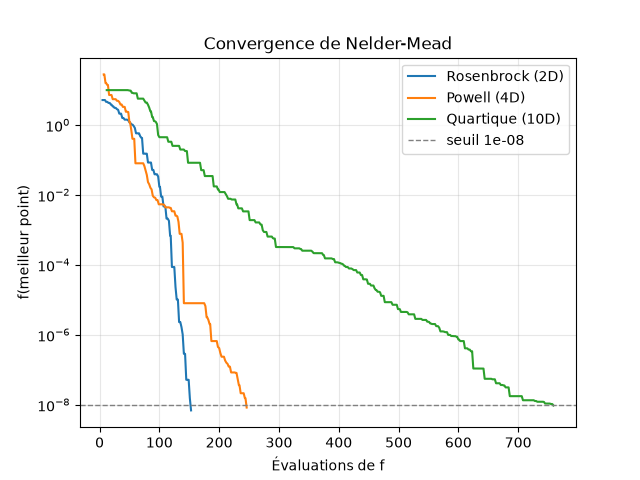

In [5]:
fig, ax = plt.subplots()

for nom, r in resultats.items():
    evaluations, valeurs = zip(*r["historique"])
    ax.semilogy(evaluations, valeurs, label=nom)

ax.axhline(SEUIL, color="grey", ls="--", lw=1, label=f"seuil {SEUIL:g}")
ax.set_xlabel("Évaluations de f")
ax.set_ylabel("f(meilleur point)")
ax.set_title("Convergence de Nelder-Mead")
ax.grid(True, which="both", alpha=0.3)
ax.legend()

plt.show()